In [1]:
import sys
import os

# Define the absolute path to the directory containing your module
module_folder_path = r'C:\Users\manue\OneDrive - University of Illinois - Urbana\Research\River corridor\inverse-river-transport\code' 


# Append the path to sys.path
sys.path.append(os.path.abspath(module_folder_path)) 
import utils
import forward
import estimators


import inspect

import numpy as np
import matplotlib.pyplot as plt

import scipy as sp
from scipy.stats import chi2

import csv

from matplotlib.colors import LogNorm

In [2]:
for module in [forward,estimators,utils]:
    print(module.__name__)
    for i, name_obj in enumerate(inspect.getmembers(module)):
        if '__' not in name_obj[0]:
            print('   ├--->',name_obj[0])
            for n,o in inspect.getmembers(name_obj[1],inspect.isfunction):
                if i != len(inspect.getmembers(module))-1:
                    print('   |       ├--->',n)
                else:
                    print('           ├--->',n)

forward
   ├---> laplace
           ├---> ADEMF_1D
           ├---> invlap
estimators
   ├---> PBI
   |       ├---> KL_coeffs
   |       ├---> drop_points_in_simplex
   |       ├---> estimate_params_NNI
   |       ├---> estimate_params_PBI
   |       ├---> get_projected_points
   |       ├---> get_projected_points_basis
   |       ├---> get_projecting_basis
   |       ├---> get_vertices_basis
   |       ├---> gs
   |       ├---> proj
   |       ├---> test_err_rand_KL_coeffs
   ├---> laplace
   |       ├---> ADEMF_1D
   ├---> moments
           ├---> ADEFO_1D
           ├---> TSM_moms_analyt
           ├---> TSM_moms_meas
utils
   ├---> dimensional_reduction
   |       ├---> KL_decomposition
   ├---> errors
   |       ├---> KL_div_func
   |       ├---> RMSD_func
   |       ├---> RMSE_func
   |       ├---> compute_errors
   ├---> invlap
   |       ├---> invlap
   ├---> load_btcs
   |       ├---> data
   ├---> synthetic
           ├---> ADEMF_1D
           ├---> generate
           ├---> 

In [3]:
help(estimators.laplace.ADEMF_1D)

Help on function ADEMF_1D in module estimators.laplace:

ADEMF_1D(t, btc, x, memory_func, bound_cond, params0, ns=10000)
    Estimates parameters of measured breakthrough curves by fitting in Laplace domain.
    - t (array): Times of measurement of concentrations
    - btc (array): Measured concentrations (same length as t)
    - memory_func (str): Either 'first order' or 'power law', others can be added editing beta_g_est_lap
    - bound_cond (str): Either 'semi-infinite-conc', 'semi-infinite-mixed', or 'infinite'
                'semi-infinite-conc' is a domain x>0 with vc(x=0,t)=M_0 delta(t)
                'semi-infinite-mixed' is a domain x>0 with vc(x=0,t)- 2 D dc/dx (x=0,t) =M_0 delta(t)
                'infinite' is a domain x>0 with vc(x=0,t)-2 D dc/dx (x=0,t) =M_0 delta(t). The solution to this problem is equivalent to the solution in the infinite domain
    - params0 (array of length 4): Initial guess of parameters. Default is v_ref and geometric mean of bounds. If bounds ar

In [4]:
with open(r"C:\Users\manue\OneDrive - University of Illinois - Urbana\Research\River corridor\inverse-river-transport\data\river_solute_tracer_data.csv", 'r') as file:
    data_reader = csv.reader(file)
    data_mat = [[cell for cell in row] for row in data_reader]
    breakthrough_curves_data = [[[data_mat[i][i_btc*5+j] for i in range(len(data_mat))] for j in range(4)] for i_btc in range(len(data_mat[0])//5)]

In [5]:
indices_valid = [i for i,btc in enumerate(breakthrough_curves_data) if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
ts_m = [np.array([float(c) for c in breakthrough_curves_data[i][0][33:] if c!='']) for i in indices_valid]
btcs_m = [np.array([float(c) for c in breakthrough_curves_data[i][3][33:] if c!='']) for i in indices_valid]
n_btcs = len(btcs_m)
for i_btc in range(n_btcs):
    if len(ts_m[i_btc])<len(btcs_m[i_btc]):
        btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
indices_unphysical = []
for i_btc in range(n_btcs):
    t,btc = ts_m[i_btc],btcs_m[i_btc]
    frac_ext = 1/3
    t_frac,btc_frac = t[btc>0][-int(len(btc[btc>0])*frac_ext):],np.log(btc[btc>0][-int(len(btc[btc>0])*frac_ext):])
    a,b = np.polyfit(t_frac,btc_frac,1)
    moms = estimators.moments.TSM_moms_meas(t,btc)
    if moms[2]<0 or a>0:
        indices_unphysical.append(indices_valid[i_btc])
for i in indices_unphysical:
    indices_valid.remove(i)
np.random.seed(42)
# indices_valid = list(np.random.choice(indices_valid,40,replace = False))

In [6]:
ts_m = [np.array([float(c) for c in breakthrough_curves_data[i][0][33:] if c!='']) for i in indices_valid]
btcs_m = [np.array([float(c) for c in breakthrough_curves_data[i][3][33:] if c!='']) for i in indices_valid]
xs_m = [breakthrough_curves_data[i][2][18] for i in indices_valid]
xs_m = [float(i) if i!='' else 0.0 for i in xs_m]
background_cs_m = [breakthrough_curves_data[i][2][25]  for i in indices_valid]
background_cs_m = [float(i) if i!='' else 0.0 for i in background_cs_m]
names_list = [breakthrough_curves_data[i][0][31]  for i in indices_valid]
n_btcs = len(ts_m)
rivers_list = [n.split(' ')[0] for n in names_list]
rivers_full_name_list = [breakthrough_curves_data[i][2][1] for i in indices_valid]
tracers_list = [' '.join(n.split(' ')[:2])+' '+''.join([j  if ('S'+j in n.split(' ')[-1]) else '' for j in list('ABCDEFGHIJKLMNOPQRSTUVWXYZ')]) for n in names_list]
unique_tracers_list = list(set(tracers_list))
_,count_tracers = np.unique([unique_tracers_list.index(i) for i in tracers_list], return_counts = True)
np.random.seed(1)
random_shuffle = np.arange(len(count_tracers))
np.random.shuffle(random_shuffle)

In [7]:
for i_btc in range(n_btcs):
    if len(ts_m[i_btc])<len(btcs_m[i_btc]):
        btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
T_= int(max([t[-1]/t[np.argmax(btc)] for t,btc in zip(ts_m,btcs_m)]))+1
print(T_)

24


In [8]:
ts_m_0 = []
btcs_m_0 = []
for i_btc in range(n_btcs):
    t,btc = ts_m[i_btc],btcs_m[i_btc]
    sorted_indices = np.argsort(t)
    t = t[sorted_indices]
    btc = btc[sorted_indices]
    t_unique,indices_unique = np.unique(t, return_index=True)
    if len(t_unique)!=len(t):
        btc_unique = np.zeros(len(indices_unique))
        for i in range(len(indices_unique)):
            if i<len(indices_unique)-1:
                btc_unique[i] = np.mean(btc[indices_unique[i]:indices_unique[i+1]])
            else:
                btc_unique[i] = np.mean(btc[indices_unique[i]:])
        t = t_unique
        btc = btc_unique
        ts_m[i_btc],btcs_m[i_btc] = t,btc
    deltat = np.median(t[1:]-t[:-1])
    t_ext = np.concatenate((np.arange(t[0],0,-deltat)[1:][::-1],t,np.arange(t[-1],max(t[-1],T_*t[np.argmax(btc)]),deltat)[1:]))
    btc_ext = np.interp(t_ext,t,btc-background_cs_m[i_btc],left = 0.0,right = 0.0)
    btc_ext = btc_ext
    ts_m_0.append(t_ext)
    btcs_m_0.append(btc_ext)

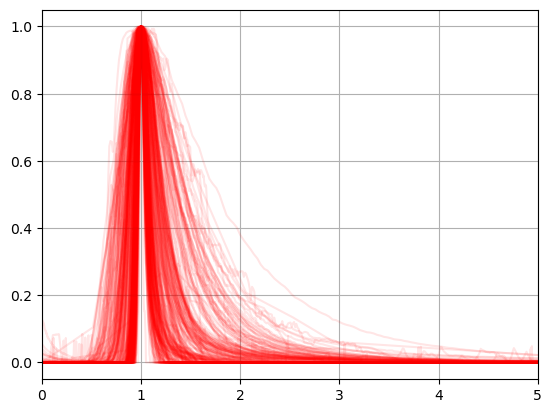

In [9]:
for i_btc in range(n_btcs):
    ts,btc = ts_m_0[i_btc],btcs_m_0[i_btc]
    plt.grid()
    plt.plot(ts/ts[np.argmax(btc)],btc/np.max(btc), c = 'r', alpha = 0.1)
    plt.xlim(0,5)

## Parameter estimation

In [10]:
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

In [11]:
memory_func = 'first order'
bound_cond = 'infinite'
only_params = False

In [12]:
vs_peak = np.array([x/ts_meas[np.argmax(measured_bt)] for ts_meas,measured_bt,x in zip(ts_m_0,btcs_m_0,xs_m)])
ts_peak = np.array([ts_meas[np.argmax(measured_bt)] for ts_meas,measured_bt,x in zip(ts_m_0,btcs_m_0,xs_m)])

In [13]:
%%time
def estimate_laplace(i_btc):
    t,btc,x, v_ref = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc], vs_peak[i_btc]
    t_pos = t[btc>0]
    btc_pos = btc[btc>0]
    params0 = np.array([vs_peak[i_btc],100.0,3.0,30.0])
    params = estimators.laplace.ADEMF_1D(t_pos,btc_pos,x,'first order','infinite',params0)
    if t[0]==0:
        btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],'first order','infinite')[:,-1]))
    else:
        btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],'first order','infinite')[:,-1]
    RMSD = utils.errors.RMSD_func(t,btc,btc_rec)
    KL_div = utils.errors.KL_div_func(t,btc,btc_rec)
    return params,RMSD,KL_div,btc_rec
output_estimate_laplace = [estimate_laplace(i_btc) for i_btc in range(n_btcs)]
params_laplace = np.array([out[0] for out in output_estimate_laplace])
RMSDs_laplace = np.array([out[1] for out in output_estimate_laplace])
KL_divs_laplace = np.array([out[2] for out in output_estimate_laplace])
btcs_rec_laplace = [out[3] for out in output_estimate_laplace]

CPU times: total: 47.5 s
Wall time: 48.5 s


In [14]:
%%time
if memory_func == 'first order':
    def estimate_moments(i_btc):
        t,btc,x = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc]
        v_prior = x/t[np.argmax(btc)]
        params0 =  np.array([v_prior,300.0,3.0,30.0])
        params = estimators.moments.ADEFO_1D(t,btc,x,'infinite',params0)
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],'first order','infinite')[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],'first order','infinite')[:,-1]
        RMSD = utils.errors.RMSD_func(t,btc,btc_rec)
        KL_div = utils.errors.KL_div_func(t,btc,btc_rec)
        return params,RMSD,KL_div,btc_rec
    output_estimate_moments = [estimate_moments(i_btc) for i_btc in range(n_btcs)]
    params_moments = np.array([out[0] for out in output_estimate_moments])
    RMSDs_moments = np.array([out[1] for out in output_estimate_moments])
    KL_divs_moments = np.array([out[2] for out in output_estimate_moments])
    btcs_rec_moments = [out[3] for out in output_estimate_moments]

CPU times: total: 47.5 s
Wall time: 48.3 s


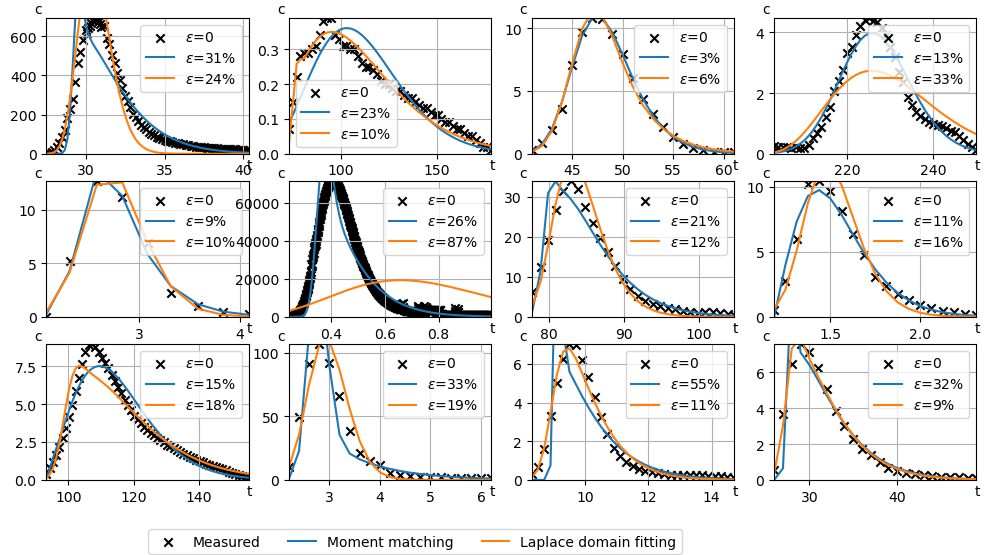

In [15]:
from matplotlib.transforms import offset_copy
# np.random.seed(1)
Nrows = 3
Ncols = 4
fig,axes = plt.subplots(nrows = Nrows, ncols = Ncols, figsize = (12,6))
np.random.seed(42)
rand_i_btcs = np.sort(np.random.choice(list(range(n_btcs)),size = Nrows*Ncols, replace = False))
j=0
for i_btc in rand_i_btcs:
    t,btc,x,est_btc_lap = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc],btcs_rec_laplace[i_btc]
    axes[j//Ncols][j%Ncols].scatter(t,btc, c='k', marker = 'x',label = '$\epsilon$=0')
    axes[j//Ncols][j%Ncols].set_ylabel('c', rotation=0)
    axes[j//Ncols][j%Ncols].set_xlabel('t', loc='right', labelpad=-10)
    if memory_func == 'first order':
        est_btc_mom = btcs_rec_moments[i_btc]
        axes[j//Ncols][j%Ncols].plot(t, est_btc_mom*np.trapezoid(btc,t)/np.trapezoid(est_btc_mom,t),label = r'$\epsilon$='+format(RMSDs_moments[i_btc],'.0%'), c = colors[0])
    
    axes[j//Ncols][j%Ncols].plot(t, est_btc_lap*np.trapezoid(btc,t)/np.trapezoid(est_btc_lap,t),label = r'$\epsilon$='+format(RMSDs_laplace[i_btc],'.0%'), c = colors[1])
    
    axes[j//Ncols][j%Ncols].set_xlim(t[btc>np.max(btc)*0.001][0],t[btc>np.max(btc)*0.01][-1])
    axes[j//Ncols][j%Ncols].set_ylim(0.0,np.max(btc))
    # axes[j//Ncols][j%Ncols].set_title(names[i_btc], loc='right',pad = -50)
    axes[j//Ncols][j%Ncols].legend()

    axes[j//Ncols][j%Ncols].grid()
    axes[j//Ncols][j%Ncols].yaxis.set_label_coords(-0.04,1.01)
    axes[j//Ncols][j%Ncols].xaxis.set_label_coords(1.02,-0.03)

    j+=1
handles, _ = axes[-1][-1].get_legend_handles_labels()
if memory_func == 'first order':
    labels = ['Measured','Moment matching', 'Laplace domain fitting']#, 'KL-DNN-MAP']
else:
    labels = ['Measured', 'Laplace domain fitting', 'KL-DNN-MAP']
fig.legend(handles, labels, loc=(0.15,0.0015), ncols = 3)

In [16]:
best_params_prior = params_laplace.copy()
if memory_func == 'first order':
    best_params_prior[RMSDs_moments<RMSDs_laplace] = params_moments[RMSDs_moments<RMSDs_laplace]

In [17]:
dim_scaling = np.concatenate((vs_peak[:,None],np.ones(n_btcs)[:,None],np.ones(n_btcs)[:,None],np.ones(n_btcs)[:,None]),axis = 1)
dimless_best_params_prior = best_params_prior/dim_scaling

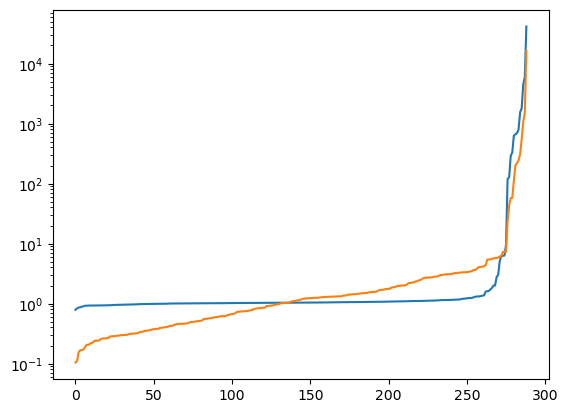

In [18]:
plt.semilogy(np.sort(dimless_best_params_prior[:,0]))
plt.semilogy(np.sort(best_params_prior[:,0]))

In [19]:
is_outlier = np.minimum(RMSDs_laplace,RMSDs_moments)>0.25
print(np.mean(is_outlier))
mean_log_params = np.mean(np.log(dimless_best_params_prior)[~is_outlier], axis=0)
cov_log_params = np.cov(np.log(dimless_best_params_prior)[~is_outlier], rowvar=0)
cov_log_params_sqrt = sp.linalg.sqrtm(cov_log_params)

0.22491349480968859


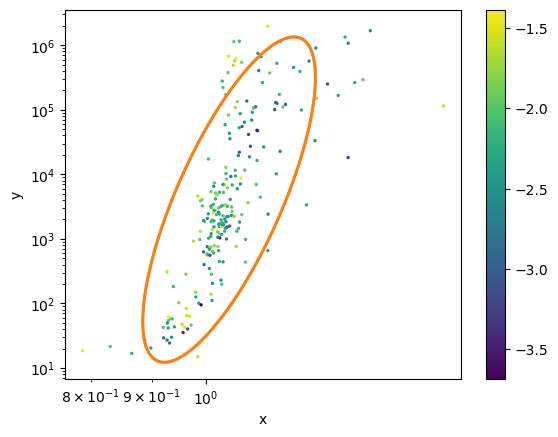

In [20]:
pars_index = [0,1]
# 1️⃣ Eigen-decomposition
eigvals, eigvecs = np.linalg.eigh(4*cov_log_params[pars_index][:,pars_index])

# 2️⃣ Parameterize unit circle
theta = np.linspace(0, 2*np.pi, 200)
circle = np.vstack((np.cos(theta), np.sin(theta)))

# 3️⃣ Scale to ellipse in log-space
ellipse_log = (
    eigvecs @ np.diag(np.sqrt(eigvals)) @ circle
    + mean_log_params[pars_index][:,None]
)

# 4️⃣ Transform back to original space
ellipse = np.exp(ellipse_log)

# 5️⃣ Plot
plt.figure()
plt.loglog(ellipse[0], ellipse[1], 'tab:orange', lw=2)
plt.loglog(ellipse[0], ellipse[1], 'tab:orange', lw=2)
plt.scatter(*dimless_best_params_prior[~is_outlier][:,pars_index].T, c = np.log(np.minimum(RMSDs_laplace,RMSDs_moments)[~is_outlier]), s = 2.0)
plt.colorbar()
plt.xscale('log')
plt.yscale('log')
plt.xlabel("x")
plt.ylabel("y")
plt.show()

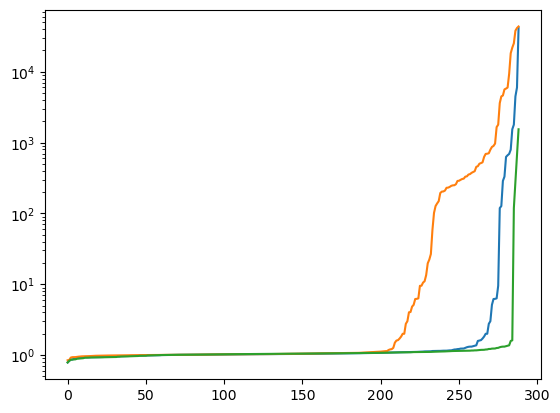

In [21]:
plt.semilogy(sorted(best_params_prior[:,0]/vs_peak))
plt.semilogy(sorted(params_laplace[:,0]/vs_peak))
plt.semilogy(sorted(params_moments[:,0]/vs_peak))

In [22]:
from scipy.stats import chi2

rivers   = np.array(rivers_full_name_list)                      # check: len(np.unique(rivers)) should be 25
logp     = np.log(dimless_best_params_prior)[:, 1:]   # log(Pe, beta*kf, kr)
ok       = np.minimum(RMSDs_laplace, RMSDs_moments) <= 0.25   # same outlier rule, all BTCs
d        = logp.shape[1]
r99      = chi2.ppf(0.99, d)

def stats(X): return X.mean(0), np.cov(X, rowvar=False)

def kl_gauss(m0, S0, m1, S1):                         # KL(N0 || N1)
    S1i = np.linalg.inv(S1); dm = m1 - m0
    return 0.5*(np.trace(S1i@S0) + dm@S1i@dm - d + np.log(np.linalg.det(S1)/np.linalg.det(S0)))

mu_all, S_all = stats(logp[ok])
sd_all = np.sqrt(np.diag(S_all))

rows = []
for r in np.unique(rivers):
    held = (rivers == r)
    tr   = ok & ~held
    mu, S = stats(logp[tr])
    te   = logp[ok & held]
    cover = np.nan
    if len(te):                                       # held-out river inside the 99% ellipsoid?
        dx = te - mu
        covered = np.sum(np.einsum('ij,jk,ik->i', dx, np.linalg.inv(S), dx) <= r99)
        all_covered_and_not = len(te)
        cover = np.mean(np.einsum('ij,jk,ik->i', dx, np.linalg.inv(S), dx) <= r99)
    rows.append(dict(river=r, n_out=int(np.sum(ok & held)),
                     dmu=(mu-mu_all)/sd_all,                  # mean shift in units of full-data std
                     vratio=np.diag(S)/np.diag(S_all),        # variance ratio
                     kl=kl_gauss(mu_all, S_all, mu, S),       # drift of the whole Gaussian
                     cover=cover,
                    covered = covered,
                    all_covered_and_not = all_covered_and_not))



In [23]:
sum([x['covered'] for x in rows if x['cover']>0.9])/sum([x['all_covered_and_not'] for x in rows if x['cover']>0.9]),sum([x['all_covered_and_not'] for x in rows if x['cover']>0.9])

(np.float64(0.9890710382513661), 183)

In [24]:
[x['cover'] for x in rows if x['river'] == 'Stringer Creek'],[x['cover'] for x in rows if x['river'] == 'Smiley Creek']

([np.float64(0.6666666666666666)], [np.float64(0.35714285714285715)])

In [25]:
np.mean(np.einsum('ij,jk,ik->i', logp[ok]-mu_all, np.linalg.inv(S_all), logp[ok]-mu_all) <= r99)

np.float64(0.96875)

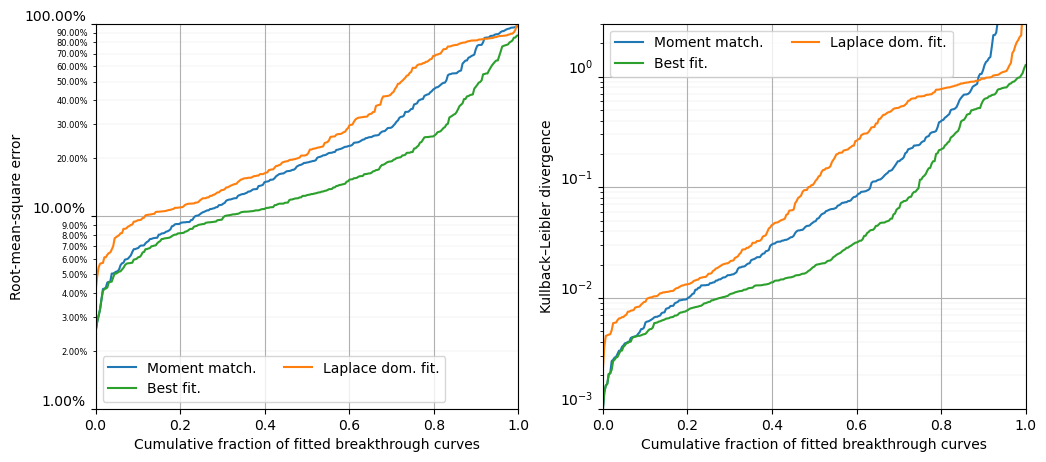

In [26]:
import matplotlib
fig,axes = plt.subplots(nrows = 1, ncols = 2, figsize = (12,5))

if memory_func == 'first order':
    axes[0].semilogy(np.linspace(0,1,len(RMSDs_moments)),np.sort(RMSDs_moments),label = 'Moment match.',c = colors[0])
    axes[0].semilogy(np.linspace(0,1,len(RMSDs_moments)),np.sort(np.minimum(RMSDs_laplace,RMSDs_moments)),label = 'Best fit.',c = colors[2])
axes[0].semilogy(np.linspace(0,1,len(RMSDs_laplace)),np.sort(RMSDs_laplace),label = 'Laplace dom. fit.',c = colors[1])


axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))
axes[0].yaxis.set_minor_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))

axes[0].tick_params(axis='y', which='major', labelsize=10)
axes[0].tick_params(axis='y', which='minor', labelsize=6)
for label in axes[0].get_yticklabels():
    label.set_verticalalignment('bottom')

axes[0].legend(ncols = 2)
axes[0].set_ylim(0.01,1.0)
axes[0].set_xlim(0,1)
axes[0].grid(which='major')
axes[0].grid(which='minor',linewidth = 0.1)
axes[0].set_xlabel('Cumulative fraction of fitted breakthrough curves')
axes[0].set_ylabel('Root-mean-square error', labelpad= 0)

if memory_func == 'first order':
    axes[1].semilogy(np.linspace(0,1,len(KL_divs_moments)),np.sort(KL_divs_moments),label = 'Moment match.',c = colors[0])
    axes[1].semilogy(np.linspace(0,1,len(KL_divs_laplace)),np.sort(np.minimum(KL_divs_laplace,KL_divs_moments)),label = 'Best fit.',c = colors[2])
axes[1].semilogy(np.linspace(0,1,len(KL_divs_laplace)),np.sort(KL_divs_laplace),label = 'Laplace dom. fit.',c = colors[1])


# axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals = 0,xmax = 1))
# axes[1].yaxis.set_minor_formatter(matplotlib.ticker.PercentFormatter(decimals = 1,xmax = 1))

axes[1].tick_params(axis='y', which='major', labelsize=10)
axes[1].tick_params(axis='y', which='minor', labelsize=6)
for label in axes[1].get_yticklabels():
    label.set_verticalalignment('bottom')

axes[1].legend(ncols = 2)
axes[1].set_ylim(0.001,3.0)
axes[1].set_xlabel('Cumulative fraction of fitted breakthrough curves')
axes[1].set_xlim(0,1)
axes[1].set_ylabel('Kullback–Leibler divergence')
axes[1].grid(which='major')
axes[1].grid(which='minor',linewidth = 0.1)

## Global optimization

In [27]:
def RMSE_t_scale(i_btc,t_scale,ts_synth,synth_btc):
    t_peak_synth = ts_synth[np.argmax(synth_btc)]
    btc_interp = np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth,synth_btc)
    a_fac = np.trapezoid(btc_interp*btcs_m_0[i_btc],x = ts_m_0[i_btc])/np.trapezoid(btc_interp**2,x = ts_m_0[i_btc])
    btc_interp_scaled = btc_interp*a_fac
    RMSD = np.sqrt(np.trapezoid((btcs_m_0[i_btc]-btc_interp_scaled)**2,x = ts_m_0[i_btc])/np.trapezoid((btcs_m_0[i_btc])**2,x = ts_m_0[i_btc]))
    return RMSD,btc_interp_scaled,a_fac

(0.0, 9.999)

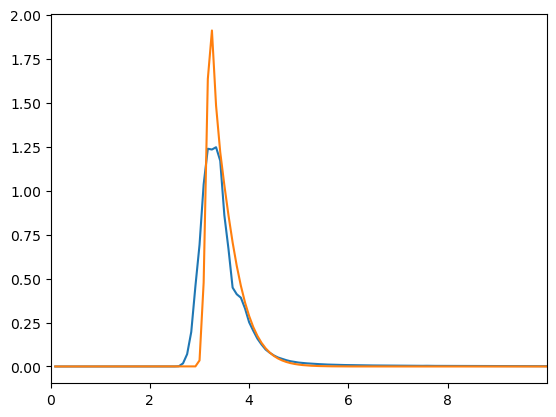

In [28]:
i_btc = 0
forward_model = lambda theta: forward.laplace.ADEMF_1D(ts_m_0[i_btc][1:],[xs_m[i_btc]],vs_peak[i_btc]*theta[0],min(theta[1],5000),theta[2]/theta[3],[theta[3],theta[3]],'first order','infinite')[:,-1]
data = btcs_m_0[i_btc][1:]/np.trapezoid(btcs_m_0[i_btc][1:],x=ts_m_0[i_btc][1:])

plt.plot(ts_m_0[i_btc][1:],btcs_m_0[i_btc][1:]/np.trapezoid(btcs_m_0[i_btc][1:],x = ts_m_0[i_btc][1:]))
plt.plot(ts_m_0[i_btc][1:],forward_model(np.exp(mean_log_params)))
plt.xlim(0,3*ts_peak[i_btc])

In [29]:
global_seed = 43

In [30]:
from scipy.optimize import NonlinearConstraint
p_value = 0.99
def constraint_ellipsoid(mu,Sigma):
    Sigma_inv = np.linalg.inv(Sigma)
    chi2_radius = chi2.ppf(p_value, 3)
        
    def ellipsoid_constraint(x):
        dx = x - mu
        return dx @ Sigma_inv @ dx
    
    constraint = NonlinearConstraint(
        ellipsoid_constraint,
        -np.inf,
        chi2_radius
    )
    return constraint

In [31]:
low_bound = mean_log_params-3*np.sqrt(np.diag(cov_log_params))
up_bound = mean_log_params+3*np.sqrt(np.diag(cov_log_params))
bounds_all = [(low_bound[0],up_bound[0])]+[(np.log(15),np.log(5500))]+[(low_bound[i],up_bound[i]) for i in range(2,4)]

### Differential Evolution

In [32]:
n_evals = 1000
popsize = 6
n_iter_DE_with_time = int(n_evals/popsize/4)
n_iter_DE = int(n_evals/popsize/3)

In [33]:
%%time
from scipy.optimize import differential_evolution
est_params_DE_with_time = np.zeros((n_btcs,4))
histories_DE_with_time = np.zeros((n_btcs,n_evals))
histories_params_DE_with_time = np.zeros((n_btcs,n_evals,4))

for i_btc in range(n_btcs):
    print(i_btc)
    history = []
    history_params = []
    
    forward_model = lambda theta: forward.laplace.ADEMF_1D(ts_m_0[i_btc][1:],[xs_m[i_btc]],vs_peak[i_btc]*theta[0],min(theta[1],5000),theta[2]/theta[3],[theta[3],theta[3]],'first order','infinite')[:,-1]
    data = btcs_m_0[i_btc][1:]/np.trapezoid(btcs_m_0[i_btc][1:],x=ts_m_0[i_btc][1:])

    def loss(theta):
        pred = forward_model(np.exp(theta)) 
        loss = utils.errors.RMSD_func(ts_m_0[i_btc][1:],data,pred)
        history.append(loss)
        history_params.append(np.exp(theta))
        return loss

    class MaxEvaluationsReached(Exception):
        pass
    
    class Objective:
        def __init__(self, max_evals):
            self.max_evals = max_evals
            self.nfev = 0
            self.best_x = None
            self.best_f = float("inf")
    
        def __call__(self, x):
            self.nfev += 1
    
            # Stop after max_evals evaluations
            if self.nfev > self.max_evals:
                raise MaxEvaluationsReached
    
            f = loss(x)
    
            # Save best point found so far
            if f < self.best_f:
                self.best_f = f
                self.best_x = x.copy()
    
            return f
    
    obj = Objective(max_evals=n_evals)

    try:
        result = differential_evolution(
            obj,bounds=bounds_all,constraints=(constraint_ellipsoid(mean_log_params,cov_log_params),),
            strategy='best1bin', 
            popsize=popsize, recombination=0.7, 
            polish=False
        )
    except MaxEvaluationsReached:
        print(f"Stopped after {obj.nfev} evaluations.")
        print("Best value:", obj.best_f)
        print("Best point:", obj.best_x)

    histories_DE_with_time[i_btc][:min(len(history),n_evals)] = history[:min(len(history),n_evals)]
    histories_params_DE_with_time[i_btc][:min(len(history),n_evals)] = history_params[:min(len(history),n_evals)]
    est_params_DE_with_time[i_btc] = np.exp(obj.best_x)

0
1
2
3
4
5
6
7
8
9
10
11
Stopped after 1001 evaluations.
Best value: 0.055870251927687443
Best point: [-2.56066874e-03  7.44647920e+00 -5.56081557e-01  2.59840263e+00]
12
13
Stopped after 1001 evaluations.
Best value: 0.025968401752321894
Best point: [0.02367448 6.97060385 0.6369383  2.27289899]
14
Stopped after 1001 evaluations.
Best value: 0.02792254568184226
Best point: [0.02157637 6.74483847 0.14356966 2.95986853]
15
Stopped after 1001 evaluations.
Best value: 0.04422306194803127
Best point: [0.02939274 7.24854077 0.67475408 3.59825609]
16
17
Stopped after 1001 evaluations.
Best value: 0.02768303181338181
Best point: [0.05020773 8.50376692 0.5102783  1.84513166]
18
Stopped after 1001 evaluations.
Best value: 0.03693727486509986
Best point: [0.03655342 6.58446272 0.34708755 2.91838645]
19
20
Stopped after 1001 evaluations.
Best value: 0.02926681364151697
Best point: [0.02691024 7.36599988 0.33837621 3.73689742]
21
Stopped after 1001 evaluations.
Best value: 0.03412749678914509
Best

In [34]:
%%time
est_params_DE = np.zeros((n_btcs,3))
histories_DE = np.zeros((n_btcs,n_evals))
histories_params_DE = np.zeros((n_btcs,n_evals,3))
Nt = 150
ts_synth = np.linspace(0,T_,T_*Nt+1)[1:]
for i_btc in range(n_btcs):
    print(i_btc)
    history = []
    history_params = []
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
        
    def loss(phi):
        theta = np.exp(phi)
        btc_synth = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],theta[1]/theta[2],[theta[2],theta[2]],'first order','infinite')[:,-1]
        output = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_synth)[0], method='bounded', bounds=range_t_scale)
        loss = output.fun
        history.append(loss)
        history_params.append(theta)
        return loss

    class MaxEvaluationsReached(Exception):
        pass
    
    class Objective:
        def __init__(self, max_evals):
            self.max_evals = max_evals
            self.nfev = 0
            self.best_x = None
            self.best_f = float("inf")
    
        def __call__(self, x):
            self.nfev += 1
    
            # Stop after max_evals evaluations
            if self.nfev > self.max_evals:
                raise MaxEvaluationsReached
    
            f = loss(x)
    
            # Save best point found so far
            if f < self.best_f:
                self.best_f = f
                self.best_x = x.copy()
    
            return f
    
    obj = Objective(max_evals=n_evals)

    try:
        result = differential_evolution(
            obj,bounds=bounds_all[1:],constraints=(constraint_ellipsoid(mean_log_params[1:],cov_log_params[1:,1:]),),
            strategy='best1bin', 
            popsize=popsize, recombination=0.7, 
            polish=False
        )
    except MaxEvaluationsReached:
        print(f"Stopped after {obj.nfev} evaluations.")
        print("Best value:", obj.best_f)
        print("Best point:", obj.best_x)


    histories_DE[i_btc][:min(len(history),n_evals)] = history[:min(len(history),n_evals)]
    histories_params_DE[i_btc][:min(len(history),n_evals)] = history_params[:min(len(history),n_evals)]
    est_params_DE[i_btc] = np.exp(obj.best_x)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
Stopped after 1001 evaluations.
Best value: 0.026557266464300396
Best point: [8.58838681 0.47134733 1.81350805]
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
24

## Local optimization

In [35]:
# %%time
est_params_local = np.zeros((n_btcs,3))
nfev_local = np.zeros(n_btcs)
histories_local = np.zeros((n_btcs,n_evals))
histories_params_local = np.zeros((n_btcs,n_evals,3))
for i_btc in range(n_btcs):
    print(i_btc)
    history = []
    history_params = []

    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    
    def loss(phi):
        theta = np.exp(phi)
        btc_synth = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],theta[1]/theta[2],[theta[2],theta[2]],'first order','infinite')[:,-1]
        output = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_synth)[0], method='bounded', bounds=range_t_scale)
        loss = output.fun
        history.append(loss)
        history_params.append(theta)
        return loss
    
    bounds = [(np.log(15),np.log(5500))]+[(mean_log_params[i+1]-cov_log_params[i+1,i+1],
               mean_log_params[i+1]+cov_log_params[i+1,i+1]) for i in range(1,3)]
    rand_x0 = np.random.multivariate_normal(mean_log_params[1:], cov_log_params[1:,1:], size = 20)
    local_result = sp.optimize.minimize(loss,x0 = rand_x0[np.all((rand_x0 >= np.array(bounds)[:,0]) & (rand_x0 <= np.array(bounds)[:,1]),axis = 1)][0],method="Nelder-Mead",options={'maxfev': n_evals},bounds = bounds)

    histories_local[i_btc][:min(len(history),n_evals)] = history[:min(len(history),n_evals)]
    histories_params_local[i_btc][:min(len(history),n_evals)] = history_params[:min(len(history),n_evals)]
    est_params_local[i_btc] = np.exp(local_result.x)
    print(local_result.success,np.min(history))

0
True 0.0586001684905737
1
True 0.057662311714107434
2
True 0.11394466949759201
3
True 0.07423384700377533
4
True 0.12188533245579415
5
True 0.03729706221930281
6
True 0.03704546454785518
7
True 0.035549191193017936
8
True 0.051401559711033565
9
True 0.05266918659264342
10
True 0.04445320968761995
11
True 0.05134025839822361
12
True 0.06324572059340822
13
True 0.02589057919836846
14
True 0.027989426062471488
15
True 0.045436075412086614
16
True 0.03770114013412482
17
True 0.02731147746335522
18
True 0.036783780617316054
19
True 0.05800811105248235
20
True 0.029049007796461055
21
True 0.03371165137287823
22
True 0.020172519453398978
23
True 0.02999887851487921
24
True 0.030702337213917345
25
True 0.04943987786410223
26
True 0.030940235619651774
27
True 0.01746834115171108
28
True 0.05074011627794972
29
True 0.04187372374515934
30
True 0.04755786691684139
31
False 0.0420677471180516
32
True 0.18014680559185467
33
True 0.09038160092105
34
True 0.03512843185667358
35
True 0.08908120197052

## No surrogate results

In [36]:
errors_local = histories_local
errors_DE = histories_DE
errors_DE_with_time = histories_DE_with_time
for i in range(n_btcs):
    errors_local[i][errors_local[i]==0] = errors_local[i][errors_local[i]!=0][-1]
    errors_DE[i][errors_DE[i]==0] = errors_DE[i][errors_DE[i]!=0][-1]
    errors_DE[i][np.where(np.isnan(errors_DE[i]))[0]] = errors_DE[i][np.where(np.isnan(errors_DE[i]))[0]-1]
    errors_DE_with_time[i][errors_DE_with_time[i]==0] = errors_DE_with_time[i][errors_DE_with_time[i]!=0][-1]

(1, 1000)

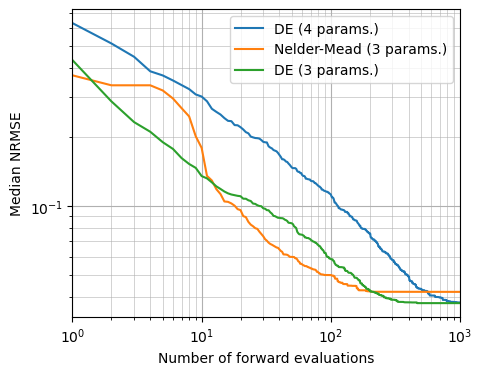

In [37]:
n_computed = n_btcs
fig,ax = plt.subplots(figsize = (5,4))
plt.loglog(np.arange(n_evals)+1,np.median(np.minimum.accumulate(errors_DE_with_time[:n_computed],axis = 1),axis = 0),label ='DE (4 params.)')
plt.loglog(np.arange(n_evals)+1,np.median(np.minimum.accumulate(errors_local[:n_computed],axis = 1),axis = 0),label ='Nelder-Mead (3 params.)')
plt.loglog(np.arange(n_evals)+1,np.median(np.minimum.accumulate(errors_DE[:n_computed],axis = 1),axis = 0),label ='DE (3 params.)')
plt.grid()
plt.xlabel('Number of forward evaluations')
plt.ylabel('Median NRMSE')
plt.legend()
plt.grid(which = 'minor', linewidth = 0.4)
plt.xlim(1,1000)

## Synth test

In [38]:
"""
Low-discrepancy (Sobol') sampling, uniform inside a p-confidence ellipsoid
of N(mu, Sigma), with the first coordinate exactly constrained to a
user-given interval [x1_lo, x1_hi].

Derivation
----------
Write Sigma = L L^T (Cholesky, L lower triangular) and let R = sqrt(chi2_p(d))
be the radius of the p-confidence ball in the whitened space. A sample is

    x = mu + L y ,        y uniform on the d-ball of radius R.

Because L is lower triangular, its first row is [L00, 0, ..., 0], so

    x0 = mu0 + L00 * y0                                            (*)

i.e. the first output coordinate depends ONLY on the first pre-rotation
coordinate y0. Two standard facts about uniform distributions on a ball
make this exact and rejection-free:

 1. Marginal of one coordinate of a uniform point on a d-ball of radius R:
        y0 = R t,   (t+1)/2 ~ Beta((d+1)/2, (d+1)/2)   on t in [-1, 1].
    Truncating y0 to an interval is therefore just truncating that Beta
    variable -- done with a single inverse-CDF (one Sobol' dimension).

 2. Conditional on y0, the remaining (y1, ..., y_{d-1}) are uniform on a
    (d-1)-ball of radius Rc = sqrt(R^2 - y0^2) -- sampled the usual way
    (Gaussian-shell direction + radius^(1/(d-1))), also via inverse-CDF,
    so d Sobol' dimensions in total (1 + (d-1) + 1 = d + 1 dimensions
    used overall, same count as the unconstrained problem).

Every generated point satisfies the constraint by construction -- no
points are discarded, so the full low-discrepancy structure of the
Sobol' sequence is preserved (unlike accept/reject filtering).
"""

import numpy as np
from scipy.stats import qmc, chi2, beta
from scipy.special import ndtri


def sobol_uniform_ellipsoid(mu, Sigma, n, p=0.99, x1_bounds=None,
                             scramble=True, seed=None):
    """
    Sobol' low-discrepancy sample of n points, uniform inside the
    p-confidence ellipsoid of N(mu, Sigma), with samples[:, 0] confined
    to x1_bounds = (lo, hi) if given.

    Parameters
    ----------
    mu : (d,) array_like
        Mean vector.
    Sigma : (d, d) array_like
        Covariance matrix (must be positive definite).
    n : int
        Number of samples requested. Internally rounded up to the next
        power of two (best practice for Sobol'), then truncated to n --
        pass n as a power of two yourself if you want to reuse the full
        low-discrepancy set later without truncation.
    p : float, optional
        Confidence level defining the ellipsoid (default 0.99).
    x1_bounds : (lo, hi) tuple, optional
        Hard bounds on the first coordinate of every returned sample.
        If None, unconstrained (equivalent to the pseudo-random version,
        but low-discrepancy).
    scramble : bool, optional
        Use Owen scrambling (recommended; avoids the fixed Sobol' grid
        artifacts and permits randomized-QMC error estimates).
    seed : int or None, optional
        Seed for the scrambling.

    Returns
    -------
    samples : (n, d) ndarray
    """
    mu = np.asarray(mu, dtype=float)
    Sigma = np.asarray(Sigma, dtype=float)
    d = mu.shape[0]

    L = np.linalg.cholesky(Sigma)
    R = np.sqrt(chi2.ppf(p, d))

    # Sobol' sequences are best generated in blocks of size 2**m.
    m_exp = int(np.ceil(np.log2(max(n, 1))))
    n_pow2 = max(1, 2 ** m_exp)

    engine = qmc.Sobol(d=d + 1, scramble=scramble, seed=seed)
    u = engine.random(n_pow2)[:n]  # (n, d+1) in (0, 1)
    eps = 1e-12
    u = np.clip(u, eps, 1 - eps)

    # ---------- 1) first coordinate: exact truncated-Beta inversion ----------
    a = b = 0.5 * (d + 1)  # Beta((d+1)/2, (d+1)/2)

    if x1_bounds is not None:
        lo, hi = x1_bounds
        if L[0, 0] == 0:
            raise ValueError("L[0,0] is zero; cannot constrain x1 this way.")
        t_lo = np.clip((lo - mu[0]) / (L[0, 0] * R), -1.0, 1.0)
        t_hi = np.clip((hi - mu[0]) / (L[0, 0] * R), -1.0, 1.0)
        if t_lo > t_hi:
            t_lo, t_hi = t_hi, t_lo
    else:
        t_lo, t_hi = -1.0, 1.0

    B_lo = beta.cdf(0.5 * (t_lo + 1.0), a, b)
    B_hi = beta.cdf(0.5 * (t_hi + 1.0), a, b)

    Bu = B_lo + u[:, 0] * (B_hi - B_lo)
    Bu = np.clip(Bu, eps, 1 - eps)
    t = 2.0 * beta.ppf(Bu, a, b) - 1.0
    y0 = R * t

    Y = np.zeros((len(u), d))
    Y[:, 0] = y0

    # ---------- 2) remaining d-1 coordinates: uniform on the sub-ball ----------
    if d > 1:
        Rc = np.sqrt(np.maximum(R ** 2 - y0 ** 2, 0.0))

        if d > 2:
            g = ndtri(u[:, 1:d])                      # (n, d-1) quasi-Gaussian
            norms = np.linalg.norm(g, axis=1, keepdims=True)
            norms[norms == 0] = 1.0
            Z = g / norms
        else:  # d == 2 -> 1-d "sphere" is just a sign
            g = ndtri(u[:, 1:2])
            Z = np.sign(g)
            Z[Z == 0] = 1.0

        rad = u[:, d] ** (1.0 / (d - 1))
        Y[:, 1:] = (Rc * rad)[:, None] * Z

    samples = mu + Y @ L.T
    return samples


In [108]:
%%time
np.random.seed(global_seed)
Nt = 150
n_synth = 1000
rand_params_synth = np.exp(sobol_uniform_ellipsoid(mean_log_params[1:], cov_log_params[1:][:,1:],
                                                   n_synth,p = p_value,x1_bounds = [np.log(15),np.log(5500)],seed = global_seed))


ts_synth = np.linspace(0,T_,T_*Nt+1)[1:]
synth_btcs = np.array([forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],theta[1]/theta[2],[theta[2],theta[2]],'first order','infinite')[:,-1] for theta in rand_params_synth])
ts_peak_synth = ts_synth[np.argmax(synth_btcs,axis = 1)]

CPU times: total: 50.9 s
Wall time: 51.4 s


### Surrogate model full

In [109]:
%%time
N = 16
btc_mean = np.mean(synth_btcs,axis = 0)
btc_diff = synth_btcs-btc_mean
C = btc_diff.T @ btc_diff / (btc_diff.shape[0] - 1)
eigvals, eigvecs = np.linalg.eigh(C)
idx = np.argsort(eigvals)[::-1]
lambdas = eigvals[idx][:N]
phis = eigvecs[:, idx][:,:N]
Zs = (btc_diff @ eigvecs[:, idx])[:,:N]

CPU times: total: 30.2 s
Wall time: 7.08 s


In [111]:
np.mean([utils.errors.RMSD_func(ts_synth,synth_btcs[i],btc_mean+phis@Zs[i]) for i in range(n_synth)])

np.float64(0.005204731042370549)

In [41]:

from scipy.spatial import Delaunay, cKDTree

def linear_ND_interp(tri, tree, x):

    x = np.asarray(x)
    ndim = tri.ndim
    simplex = tri.find_simplex(x)

    if simplex >= 0:
        # Standard barycentric interpolation
        T = tri.transform[simplex, :ndim]
        r = tri.transform[simplex, ndim]

        bary = T @ (x - r)
        weights = np.concatenate([bary, [1 - bary.sum()]])
        vertices = tri.simplices[simplex]

    else:
        # Outside convex hull → nearest vertex
        dist, nearest = tree.query(x)

        vertices = np.zeros(ndim + 1, dtype=int)
        vertices[0] = nearest

        # fill remaining slots with any other indices
        remaining = np.setdiff1d(np.arange(len(tri.points)), [nearest])
        vertices[1:] = remaining[:ndim]

        weights = np.zeros(ndim + 1)
        weights[0] = 1.0
        # vertices, weights = np.zeros(ndim+1).astype(int), np.zeros(ndim+1)+np.nan

    return vertices, weights


def Zs_interpolate(pars,tri,tree,Zs):
    ND_interp_vertices,ND_interp_weights = linear_ND_interp(tri,tree,pars)
    return ND_interp_weights@Zs[ND_interp_vertices],ND_interp_weights@ts_peak_synth[ND_interp_vertices]
    
triangulation = Delaunay(np.log(rand_params_synth))
tree = cKDTree(np.log(rand_params_synth))

In [42]:
%%time
RMSDs_NNI_full = np.zeros(n_btcs)
est_params_NNI_full = np.zeros((n_btcs,5))
btcs_recons_NNI_full = []
for i_btc in range(n_btcs):
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    outs_RMSE_t_scale = [sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,synth_btcs[i])[0], method='bounded', bounds=range_t_scale) for i in range(n_synth)]
    t_scales = [out.x for out in outs_RMSE_t_scale]
    RMSDs = [out.fun for out in outs_RMSE_t_scale]
    btcs_interp_scaled = [RMSE_t_scale(i_btc,t_scales[i],ts_synth,synth_btcs[i])[1] for i in range(n_synth)]
    a_facs_est = np.array([RMSE_t_scale(i_btc,t_scales[i],ts_synth,synth_btcs[i])[2] for i in range(n_synth)])
    RMSDs_NNI_full[i_btc] = np.min(RMSDs)
    NNI_index = np.argmin(RMSDs)
    vs_est = xs_m[i_btc]/(t_scales/ts_peak_synth)
    est_pars = np.concatenate(([a_facs_est[NNI_index],vs_est[NNI_index]],rand_params_synth[NNI_index]))
    est_params_NNI_full[i_btc] = est_pars
    if ts_m[i_btc][0]>0:
        btcs_recons_NNI_full.append(forward.laplace.ADEMF_1D(ts_m[i_btc],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],'first order','infinite')[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])
    else:
        btcs_recons_NNI_full.append(np.concatenate(([0],forward.laplace.ADEMF_1D(ts_m[i_btc][1:],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],'first order','infinite')[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])))
    print(i_btc,np.min(RMSDs))

0 0.07715485067815347
1 0.061843003214497205
2 0.09228171388899081
3 0.08548770539703239
4 0.09963847804027397
5 0.052698017907206345
6 0.045801862406840185
7 0.04902193113311595
8 0.04493032789109466
9 0.05699958141557547
10 0.04866585322487018
11 0.07542649649826547
12 0.054105033065329156
13 0.04293475695788173
14 0.028531510343055625
15 0.04514425949752938
16 0.04905029082836746
17 0.08354013103427069
18 0.05974665315203494
19 0.07573568015994868
20 0.03895170207374147
21 0.06471255012756987
22 0.03660425550345347
23 0.05351901414977003
24 0.03509611137075146
25 0.06134214941443239
26 0.04111519562865762
27 0.027025931018780754
28 0.05532877685856489
29 0.04606864626316403
30 0.05315828251016265
31 0.04585273053032539
32 0.11625298956204586
33 0.09488884684451196
34 0.04864638841654781
35 0.10165009510324122
36 0.14864913409031347
37 0.08024334330409572
38 0.04687140475209506
39 0.0497209828799722
40 0.05548342900227202
41 0.25654968774208864
42 0.0293066088489179
43 0.031700550020

#### Surrogate test

In [43]:
def Zs_interpolate(pars,tri,tree,Zs,ts_peak_synth):
    ND_interp_vertices,ND_interp_weights = linear_ND_interp(tri,tree,pars)
    return ND_interp_weights@Zs[ND_interp_vertices],ND_interp_weights@ts_peak_synth[ND_interp_vertices]

In [44]:
%%time
errors_test_LOO = np.zeros(n_synth)
for i in range(n_synth):
    Zs_test_i,t_peak_test_i = Zs_interpolate(np.log(rand_params_synth[i]),Delaunay(np.log(np.delete(rand_params_synth,i,axis = 0))),cKDTree(np.log(np.delete(rand_params_synth,i,axis = 0))),np.delete(Zs,i,axis = 0),np.delete(ts_peak_synth,i))
    btc_synth_test_i = np.interp(ts_synth,ts_synth*t_peak_test_i/ts_peak_synth[i],btc_mean+Zs_test_i@phis.T)
    error_test = utils.errors.RMSD_func(ts_synth,synth_btcs[i],btc_synth_test_i)
    errors_test_LOO[i] = error_test

CPU times: total: 2min 9s
Wall time: 2min 18s


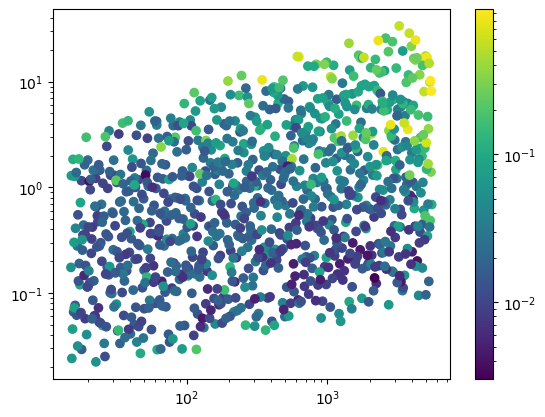

In [45]:
plt.scatter(rand_params_synth[:,0],rand_params_synth[:,1],c=errors_test_LOO,norm = LogNorm())
plt.colorbar()
plt.xscale('log')
plt.yscale('log')

In [46]:
def test_errors_interpolate(pars,tri,tree,errors_test):
    ND_interp_vertices,ND_interp_weights = linear_ND_interp(tri,tree,pars)
    return ND_interp_weights@errors_test[ND_interp_vertices]

#### Surrogate model optimization full

In [47]:
def RMSE_t_scale_Z(i_btc,t_scale,Zs_i,t_peak_synth_interp,btc_mean,phis):
    btc_mean_resampled = np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth_interp,btc_mean)
    phis_resampled = np.array([np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth_interp,phi) for phi in phis.T]).T
    btc_interp =  (btc_mean_resampled+Zs_i@(phis_resampled).T)
    a_fac = np.trapezoid(btc_interp*btcs_m_0[i_btc],x = ts_m_0[i_btc])/np.trapezoid(btc_interp**2,x = ts_m_0[i_btc])
    btc_interp_scaled = btc_interp*a_fac
    RMSD = np.sqrt(np.trapezoid((btcs_m_0[i_btc]-btc_interp_scaled)**2,x = ts_m_0[i_btc])/np.trapezoid((btcs_m_0[i_btc])**2,x = ts_m_0[i_btc]))
    return RMSD,btc_interp_scaled

In [48]:
def constraint_ellipsoid_modified(mu,Sigma):
    Sigma_inv = np.linalg.inv(Sigma)
    chi2_radius = chi2.ppf(p_value, 3)
        
    def ellipsoid_constraint(x):
        dx = x[1:] - mu
        return dx @ Sigma_inv @ dx
    
    constraint = NonlinearConstraint(
        ellipsoid_constraint,
        -np.inf,
        chi2_radius
    )
    return constraint

In [49]:
%%time
RMSDs_linear_full = np.zeros((n_btcs))
est_params_linear_full = np.zeros((n_btcs,5))
btcs_recons_linear_full = []

for i_btc in range(n_btcs):
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    
    triangulation = Delaunay(np.log(rand_params_synth))
    tree = cKDTree(np.log(rand_params_synth))
    def loss(par):
        Zs_i,t_peak_synth_interp = Zs_interpolate(par[1:],triangulation,tree,Zs,ts_peak_synth)
        loss_i = RMSE_t_scale_Z(i_btc,par[0],Zs_i,t_peak_synth_interp,btc_mean,phis)[0]**2
        error_est = test_errors_interpolate(par[1:],triangulation,tree,errors_test_LOO)**2
        return loss_i+error_est
    result_DE_linear = differential_evolution(func=loss, bounds=[(range_t_scale[0],range_t_scale[1])]+bounds_all[1:],constraints=(constraint_ellipsoid_modified(mean_log_params[1:],cov_log_params[1:,1:]),),
        strategy='best1bin',popsize=20, recombination=0.7, seed=global_seed)
    est_linear = np.exp(result_DE_linear.x[1:])
    btc_linear = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,est_linear[0],est_linear[1]/est_linear[2],[est_linear[2],est_linear[2]],'first order','infinite')[:,-1]
    t_scale_linear = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_linear)[0], method='bounded', bounds=range_t_scale).x
    RMSD,btc_interp_scaled,a_fac = RMSE_t_scale(i_btc,t_scale_linear,ts_synth,btc_linear)
    v_est = xs_m[i_btc]/(t_scale_linear/ts_synth[np.argmax(btc_linear)])
    est_pars = [a_fac,v_est,*est_linear]
    est_params_linear_full[i_btc] = est_pars
    RMSDs_linear_full[i_btc] = min(RMSDs_NNI_full[i_btc],RMSD)
    if ts_m[i_btc][0]>0:
        btcs_recons_linear_full.append(forward.laplace.ADEMF_1D(ts_m_0[i_btc],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],'first order','infinite')[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])
    else: 
        btcs_recons_linear_full.append(np.concatenate(([0],forward.laplace.ADEMF_1D(ts_m_0[i_btc][1:],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],'first order','infinite')[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])))
    print(i_btc,RMSDs_NNI_full[i_btc],RMSD,np.sqrt(result_DE_linear.fun))

C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\scipy\optimize\_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


0 0.07715485067815347 0.059558081066375244 0.06344646743467433
1 0.061843003214497205 0.05782505692708142 0.05849384142902242
2 0.09228171388899081 0.07711934579350294 0.0774589969819867
3 0.08548770539703239 0.07481729522914643 0.0747048418068422
4 0.09963847804027397 0.07756879004789992 0.07618490412391647
5 0.052698017907206345 0.03766903281185494 0.04399651202387582
6 0.045801862406840185 0.03986957170898974 0.041176405632673344
7 0.04902193113311595 0.03851945962564003 0.042253408530214205
8 0.04493032789109466 0.03309050011982199 0.037456406375335656
9 0.05699958141557547 0.0428404083271625 0.04593686270464113
10 0.04866585322487018 0.0448437249157163 0.046656500177321224
11 0.07542649649826547 0.053271841921380646 0.04967288131179227
12 0.054105033065329156 0.05252220187495609 0.050049465190902594
13 0.04293475695788173 0.03443700998307261 0.050078815158714596


C:\Users\manue\anaconda3\envs\GenUse0\Lib\site-packages\scipy\optimize\_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


14 0.028531510343055625 0.029026730126775313 0.039925671016119615
15 0.04514425949752938 0.051925620759876355 0.057334367031851345
16 0.04905029082836746 0.042644041488216836 0.047537632237836164
17 0.08354013103427069 0.049939026665229765 0.04857151066051701
18 0.05974665315203494 0.0378389744834168 0.044707561085030635
19 0.07573568015994868 0.05892463125710586 0.06324733437688076
20 0.03895170207374147 0.03466877686089923 0.0398569173567833
21 0.06471255012756987 0.06693395543227673 0.07336600835706004
22 0.03660425550345347 0.02470539915537393 0.028828348406096237
23 0.05351901414977003 0.03090312314494931 0.0352333452230205
24 0.03509611137075146 0.039194078133717815 0.043225433347450305
25 0.06134214941443239 0.05118824068818218 0.05264848787395078
26 0.04111519562865762 0.032347277902305197 0.03653867012562455
27 0.027025931018780754 0.028852714556583968 0.03940319134672583
28 0.05532877685856489 0.04765491457000728 0.058082978960686545
29 0.04606864626316403 0.04236036337227282

0.05698631077379913 0.052511529568942374
0.04786705433885552 0.04249801866875845


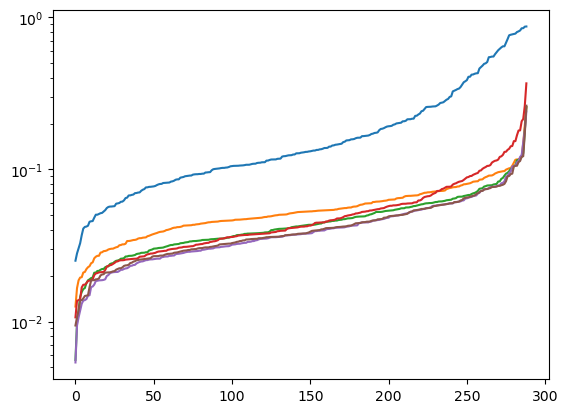

In [50]:
plt.semilogy(np.sort(np.minimum(RMSDs_laplace,RMSDs_moments)))
plt.semilogy(np.sort(RMSDs_NNI_full))
plt.semilogy(np.sort(RMSDs_linear_full))
plt.semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_local]))
plt.semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_DE]))
plt.semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_DE_with_time]))
print(np.mean(RMSDs_NNI_full),np.median(RMSDs_NNI_full))
print(np.mean(RMSDs_linear_full),np.median(RMSDs_linear_full))

### Partial synthetic set

In [51]:
ns_synth_interm_linear = np.unique(np.logspace(np.log10(5),np.log10(1000),16).round().astype(int))


In [52]:
%%time
N = 16
Zs_all = np.zeros((len(ns_synth_interm_linear),n_synth,N))
phis_all = np.zeros((len(ns_synth_interm_linear),len(ts_synth),N))
btc_mean_all = np.zeros((len(ns_synth_interm_linear),len(ts_synth)))
lambdas_all = np.zeros((len(ns_synth_interm_linear),N))
for j,n in enumerate(ns_synth_interm_linear):
    btc_mean = np.mean(synth_btcs[:n],axis = 0)
    btc_diff = synth_btcs[:n]-btc_mean
    C = btc_diff.T @ btc_diff / (btc_diff.shape[0] - 1)
    eigvals, eigvecs = np.linalg.eigh(C)
    idx = np.argsort(eigvals)[::-1]
    N_terms = min(N,n)
    lambdas = eigvals[idx][:N_terms]
    phis = eigvecs[:, idx][:,:N_terms]
    Zs = (btc_diff @ eigvecs[:, idx])[:,:N_terms]
    Zs_all[j,:n,:N_terms] = Zs
    phis_all[j,:,:N_terms] = phis
    btc_mean_all[j] = btc_mean
    lambdas_all[j,:N_terms] = lambdas

CPU times: total: 10min 38s
Wall time: 2min 5s


In [53]:
%%time
RMSDs_NNI = np.zeros((n_btcs,n_synth))
est_params_NNI = np.zeros((n_btcs,n_synth,5))
for i_btc in range(n_btcs):
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    outs_RMSE_t_scale = [sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,synth_btcs[i])[0], method='bounded', bounds=range_t_scale) for i in range(n_synth)]
    t_scales = [out.x for out in outs_RMSE_t_scale]
    RMSDs = [out.fun for out in outs_RMSE_t_scale]
    btcs_interp_scaled = [RMSE_t_scale(i_btc,t_scales[i],ts_synth,synth_btcs[i])[1] for i in range(n_synth)]
    a_facs_est = np.array([RMSE_t_scale(i_btc,t_scales[i],ts_synth,synth_btcs[i])[2] for i in range(n_synth)])
    RMSDs_NNI[i_btc] = np.minimum.accumulate(RMSDs)
    NNI_indices = np.array([np.argmin(RMSDs[:i+1]) for i in range(n_synth)])
    vs_est = xs_m[i_btc]/(t_scales/ts_peak_synth)
    est_params_NNI[i_btc] = np.concatenate((a_facs_est[NNI_indices][:,None],vs_est[NNI_indices][:,None],rand_params_synth[NNI_indices]),axis = 1)
    print(i_btc,np.min(RMSDs))

0 0.07715485067815347
1 0.061843003214497205
2 0.09228171388899081
3 0.08548770539703239
4 0.09963847804027397
5 0.052698017907206345
6 0.045801862406840185
7 0.04902193113311595
8 0.04493032789109466
9 0.05699958141557547
10 0.04866585322487018
11 0.07542649649826547
12 0.054105033065329156
13 0.04293475695788173
14 0.028531510343055625
15 0.04514425949752938
16 0.04905029082836746
17 0.08354013103427069
18 0.05974665315203494
19 0.07573568015994868
20 0.03895170207374147
21 0.06471255012756987
22 0.03660425550345347
23 0.05351901414977003
24 0.03509611137075146
25 0.06134214941443239
26 0.04111519562865762
27 0.027025931018780754
28 0.05532877685856489
29 0.04606864626316403
30 0.05315828251016265
31 0.04585273053032539
32 0.11625298956204586
33 0.09488884684451196
34 0.04864638841654781
35 0.10165009510324122
36 0.14864913409031347
37 0.08024334330409572
38 0.04687140475209506
39 0.0497209828799722
40 0.05548342900227202
41 0.25654968774208864
42 0.0293066088489179
43 0.031700550020

In [54]:
%%time
errors_test_LOO_partial = []
for j,n_synth_interm_linear in enumerate(ns_synth_interm_linear):
    errors_test_LOO_partial_i = np.zeros(n_synth)
    for i in range(n_synth_interm_linear):
        triangulation = Delaunay(np.log(rand_params_synth[:n_synth_interm_linear]))
        tree = cKDTree(np.log(rand_params_synth[:n_synth_interm_linear]))
        Zs_test_i,t_peak_test_i = Zs_interpolate(np.log(rand_params_synth[i]),
                                                 Delaunay(np.log(np.delete(rand_params_synth[:n_synth_interm_linear],i,axis = 0))),
                                                 cKDTree(np.log(np.delete(rand_params_synth[:n_synth_interm_linear],i,axis = 0))),
                                                 np.delete(Zs_all[j][:n],i,axis = 0),
                                                 np.delete(ts_peak_synth[:n_synth_interm_linear],i))
        btc_synth_test_i = np.interp(ts_synth,ts_synth*t_peak_test_i/ts_peak_synth[i],btc_mean_all[j]+Zs_test_i@phis_all[j].T)
        error_test = utils.errors.RMSD_func(ts_synth,synth_btcs[i],btc_synth_test_i)
        errors_test_LOO_partial_i[i] = error_test
    errors_test_LOO_partial.append(errors_test_LOO_partial_i)
    print(n_synth_interm_linear)

5
7
10
14
21
29
42
59
84
120
171
243
347
493
702
1000
CPU times: total: 4min 40s
Wall time: 4min 56s


In [55]:
def RMSE_t_scale_Z(i_btc,t_scale,Zs_i,t_peak_synth_interp,btc_mean,phis):
    btc_mean_resampled = np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth_interp,btc_mean)
    phis_resampled = np.array([np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth_interp,phi) for phi in phis.T]).T
    btc_interp =  (btc_mean_resampled+Zs_i@(phis_resampled).T)
    a_fac = np.trapezoid(btc_interp*btcs_m_0[i_btc],x = ts_m_0[i_btc])/np.trapezoid(btc_interp**2,x = ts_m_0[i_btc])
    btc_interp_scaled = btc_interp*a_fac
    RMSD = np.sqrt(np.trapezoid((btcs_m_0[i_btc]-btc_interp_scaled)**2,x = ts_m_0[i_btc])/np.trapezoid((btcs_m_0[i_btc])**2,x = ts_m_0[i_btc]))
    return RMSD,btc_interp_scaled

In [56]:
%%time


RMSDs_linear = np.zeros((n_btcs,len(ns_synth_interm_linear)))
est_params_linear = np.zeros((n_btcs,len(ns_synth_interm_linear),5))

for i_btc in range(n_btcs):
    np.random.seed(global_seed)
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]

    for j,n_synth_interm_linear in enumerate(ns_synth_interm_linear):
        
        triangulation = Delaunay(np.log(rand_params_synth[:n_synth_interm_linear]))
        tree = cKDTree(np.log(rand_params_synth[:n_synth_interm_linear]))
        def loss(par):
            Zs_i,t_peak_synth_interp = Zs_interpolate(par[1:],triangulation,tree,Zs_all[j],ts_peak_synth[:n_synth_interm_linear])
            loss_i = RMSE_t_scale_Z(i_btc, par[0], Zs_i, t_peak_synth_interp,btc_mean_all[j], phis_all[j])[0]**2
            error_est = test_errors_interpolate(par[1:],triangulation,tree,errors_test_LOO_partial[j])**2
            return loss_i+error_est
        result_DE_linear = differential_evolution(func=loss, bounds=[(range_t_scale[0],range_t_scale[1])]+bounds_all[1:],constraints=(constraint_ellipsoid_modified(mean_log_params[1:],cov_log_params[1:,1:]),),
            strategy='best1bin',popsize=20, recombination=0.7, seed=global_seed)
        est_linear = np.exp(result_DE_linear.x[1:])
        
        btc_linear = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,est_linear[0],est_linear[1]/est_linear[2],[est_linear[2],est_linear[2]],'first order','infinite')[:,-1]
        t_scale_linear = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_linear)[0], method='bounded', bounds=range_t_scale).x
        RMSD,btc_interp_scaled,a_fac = RMSE_t_scale(i_btc,t_scale_linear,ts_synth,btc_linear)
        v_est = xs_m[i_btc]/(t_scale_linear/ts_synth[np.argmax(btc_linear)])
        est_params_linear[i_btc,j] = [a_fac,v_est,*est_linear]
        RMSDs_linear[i_btc,j] = min(RMSDs_NNI[i_btc,n_synth_interm_linear-1],RMSD)
    print(i_btc,RMSDs_NNI[i_btc,-1],RMSD,np.sqrt(result_DE_linear.fun))    

0 0.07715485067815347 0.0595855786533828 0.06344321216543375
1 0.061843003214497205 0.057831763213022004 0.05849728366843068
2 0.09228171388899081 0.07711934579350294 0.0774589969819867
3 0.08548770539703239 0.07486160689515971 0.07470484180692762
4 0.09963847804027397 0.07750684986090597 0.07618497269293603
5 0.052698017907206345 0.03766858872752422 0.04399653937727601
6 0.045801862406840185 0.03978128450196691 0.0411923547871209
7 0.04902193113311595 0.03851839721986393 0.04225340049213633
8 0.04493032789109466 0.033090827146528 0.03745640832448184
9 0.05699958141557547 0.04284766999770269 0.04593733050856941
10 0.04866585322487018 0.04484161312430672 0.04665650017748257
11 0.07542649649826547 0.05327157962201781 0.04967289218299684
12 0.054105033065329156 0.052513237279646054 0.05004985721354788
13 0.04293475695788173 0.034436948835766854 0.05007881631339364
14 0.028531510343055625 0.029027499929565864 0.03992526731895655
15 0.04514425949752938 0.05192560935526275 0.0573343670248844

In [57]:
# np.savez('histories_'+str(global_seed)+'.npz',DE_with_time = histories_DE_with_time,local = histories_local,DE = histories_DE, NNI = RMSDs_NNI, Linear = RMSDs_linear,  ns_synth_interm_linear = ns_synth_interm_linear)


In [58]:
est_params_list = [est_params_DE_with_time,est_params_local,est_params_DE,est_params_NNI,est_params_linear]
[i.shape for  i in est_params_list]

[(289, 4), (289, 3), (289, 3), (289, 1000, 5), (289, 16, 5)]

In [59]:
all_est_params_local = np.zeros((n_btcs,5))
all_est_params_DE = np.zeros((n_btcs,5))
all_est_params_DE_with_time = np.zeros((n_btcs,5))
all_est_params_NNI = np.zeros((n_btcs,5))
all_est_params_linear = np.zeros((n_btcs,5))

all_est_params_list = [all_est_params_DE_with_time,all_est_params_local,all_est_params_DE,all_est_params_NNI,all_est_params_linear]

RMSD_final_local = np.zeros((n_btcs))
RMSD_final_DE = np.zeros((n_btcs))
RMSD_final_DE_with_time = np.zeros((n_btcs))
RMSD_final_NNI = np.zeros((n_btcs))
RMSD_final_linear = np.zeros((n_btcs))

RMSD_final_all = [RMSD_final_local,RMSD_final_DE,RMSD_final_DE_with_time,RMSD_final_NNI,RMSD_final_linear]

est_params_list = [est_params_DE_with_time,est_params_local,est_params_DE,est_params_NNI,est_params_linear]
for i_btc in range(n_btcs):
    print(i_btc)
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]

    for i in range(5):
        if i in [0,1,2]:
            est_params = est_params_list[i][i_btc,-3:] 
        elif i == 3:
            est_params = est_params_list[i][i_btc,np.argmin(RMSDs_NNI[i_btc]),-3:] 
        elif i == 4:
            est_params = est_params_list[i][i_btc,-1,-3:] 
        est_params[est_params>5000] = 5000.0
        all_est_params_list[i][i_btc,2:] = est_params            
        if i == 0:
            v_est = est_params_list[i][i_btc,0]*vs_peak[i_btc]
        else:
            btc_est = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,est_params[0],est_params[1]/est_params[2],[est_params[2],est_params[2]],'first order','infinite')[:,-1]
            t_scale_est = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_est)[0], method='bounded', bounds=range_t_scale).x
            v_est = xs_m[i_btc]/(t_scale_est/ts_synth[np.argmax(btc_est)])
        btc_synth = forward.laplace.ADEMF_1D(ts_m_0[i_btc][ts_m_0[i_btc]>0],[xs_m[i_btc]],v_est,
                                             est_params[0],est_params[1]/est_params[2],[est_params[2],est_params[2]],'first order','infinite')[:,-1]
        a = np.trapezoid(btcs_m_0[i_btc][ts_m_0[i_btc]>0] * btc_synth,ts_m_0[i_btc][ts_m_0[i_btc]>0]) / np.trapezoid(btc_synth**2,ts_m_0[i_btc][ts_m_0[i_btc]>0])
        all_est_params_list[i][i_btc] = [a*v_est,v_est,*est_params]
        RMSD_final_all[i][i_btc] = utils.errors.RMSD_func(ts_m_0[i_btc][ts_m_0[i_btc]>0],btcs_m_0[i_btc][ts_m_0[i_btc]>0],btc_synth)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

In [60]:
best_all_params = np.array([np.array(all_est_params_list)[np.argmin(RMSD_final_all,axis = 0)[i_btc],i_btc] for i_btc in range(n_btcs)])

In [61]:
# %%time
est_params_ref = np.zeros((n_btcs,5))
max_n_fev = 100
histories_ref = np.zeros((n_btcs,max_n_fev))

for i_btc in range(n_btcs):
    print(i_btc)
    forward_sol = lambda params: forward.laplace.ADEMF_1D(ts_m_0[i_btc][ts_m_0[i_btc]>0],[xs_m[i_btc]],params[0],
                                             params[1],params[2]/params[3],[params[3],params[3]],'first order','infinite')[:,-1]
    history = []
    def loss(params):
        btc_synth = forward_sol(params)
        loss = utils.errors.RMSD_func(ts_m_0[i_btc][ts_m_0[i_btc]>0],btcs_m_0[i_btc][ts_m_0[i_btc]>0],btc_synth)
        history.append(loss)
        return loss

    local_result = sp.optimize.minimize(loss,x0 = best_all_params[i_btc][1:],method="Nelder-Mead",options={'maxfev': max_n_fev},
                                        bounds = sp.optimize.Bounds([0,0,0,0], [np.inf,np.inf,np.inf,np.inf]))
    est_4_params = local_result.x
    btc_synth = forward_sol(est_4_params)
    a = np.trapezoid(btcs_m_0[i_btc][ts_m_0[i_btc]>0] * btc_synth,ts_m_0[i_btc][ts_m_0[i_btc]>0]) / np.trapezoid(btc_synth**2,ts_m_0[i_btc][ts_m_0[i_btc]>0])
    histories_ref[i_btc][:len(history)] = history[:max_n_fev]
    est_params_ref[i_btc] = [a*est_4_params[0],*est_4_params] 
    print(np.min(np.array(history)[np.array(history)>0.0]),np.array(RMSD_final_all)[:,i_btc])

0
0.058630176963898877 [0.0586961  0.05863929 0.05866145 0.07711954 0.05963926]
1
0.057512851250567966 [0.05754126 0.0575735  0.05759532 0.06093695 0.05760818]
2
0.07655988133445985 [0.07664529 0.11147445 0.07682103 0.09349748 0.07704073]
3
0.07410715946992591 [0.07429257 0.07417752 0.07418287 0.08624202 0.07477576]
4
0.07635129581437741 [0.07655713 0.11915466 0.07661512 0.10021256 0.07750488]
5
0.037285184408771196 [0.0373598  0.03729728 0.03729463 0.05269011 0.03777806]
6
0.0370177967216853 [0.03705749 0.03716839 0.03721609 0.04614348 0.03974948]
7
0.035905592525328996 [0.03595458 0.03595455 0.03598147 0.04884511 0.03818472]
8
0.029424359186162267 [0.02953472 0.05151295 0.02961831 0.04534994 0.03300932]
9
0.04117649555957331 [0.0411765  0.05282183 0.04130101 0.05656096 0.04274608]
10
0.04433678087332931 [0.04436337 0.04438129 0.04452458 0.04894732 0.0450395 ]
11
0.05125252104864674 [0.05587025 0.051303   0.05131382 0.07708803 0.05327821]
12
0.05017930918805486 [0.05025458 0.06323087 

In [62]:
np.mean(RMSD_final_all[2]<RMSD_final_all[4])

np.float64(0.9584775086505191)

(0.02, 0.2)

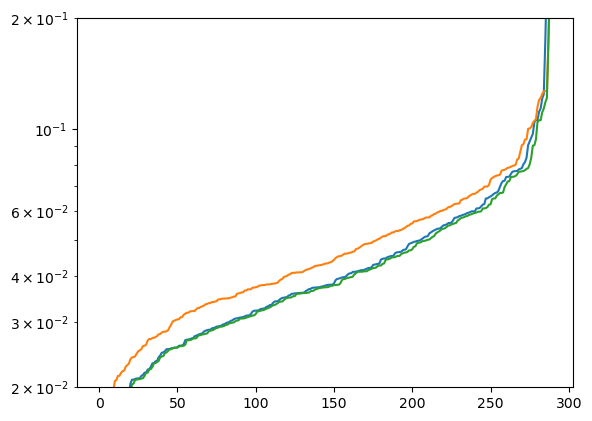

In [63]:
for j in [2,4]:
    plt.semilogy(np.sort(RMSD_final_all[j]))
plt.semilogy(np.sort(np.min(RMSD_final_all,axis = 0)))
plt.ylim(0.02,0.2)

In [64]:
for i in range(5):
    print(np.median(RMSD_final_all[i]))

0.037783825161959154
0.042053441690302576
0.03763428612793847
0.05267730560093467
0.04312973382998363


In [65]:
for j in range(5):
    print(format(np.mean(np.abs((all_est_params_list[j][:,1]/est_params_ref[:,1])-1)),'.2%'),
         format(np.mean(np.abs(1/all_est_params_list[j][:,2]-1/est_params_ref[:,2])),'.2e'),
         format(np.mean(np.abs(all_est_params_list[j][:,3]-est_params_ref[:,3])),'.2f'),
         format(np.mean(np.abs(all_est_params_list[j][:,4]-est_params_ref[:,4])),'.2f'))

0.84% 3.59e-04 0.30 1.72
2.01% 1.86e-03 0.41 7.25
0.49% 3.28e-04 0.16 1.61
1.71% 9.40e-04 0.58 4.37
1.48% 8.23e-04 0.50 3.91


In [66]:
for j in range(5):
    print(*[format(2*np.mean(np.abs(all_est_params_list[j][:,i]-est_params_ref[:,i])
                                 /(np.abs(all_est_params_list[j][:,i])+np.abs(est_params_ref[:,i]))),'.2%') for i in range(1,5)])

0.83% 12.64% 12.55% 6.83%
1.89% 23.50% 27.16% 25.86%
0.47% 8.55% 8.58% 6.23%
1.70% 26.86% 34.17% 23.72%
1.53% 25.16% 29.41% 18.15%


array([0.99721141, 1.00006551, 1.00043114, 1.00068437, 1.00109931,
       1.00062942, 1.00212653, 1.00281323, 1.00304898, 1.00235082,
       1.00024446, 1.00251931, 1.00148949, 1.00258171, 0.99875328,
       0.97890533, 0.99436954, 1.00816017, 0.99937118, 0.99968738,
       0.98362373, 0.98547502, 0.99485952, 0.99972906, 0.98994729,
       1.00257397, 0.9975807 , 0.98987204, 0.98157103, 0.97738515,
       0.99428173, 0.99708952, 1.00097206, 0.88486654, 0.98758212,
       0.99827968, 0.99703108, 0.99642805, 0.90624594, 1.00082324,
       1.00384503, 0.99917095, 0.95996971, 0.9988178 , 0.99885047,
       1.0058404 , 0.80899865, 0.99023585, 0.96342995, 1.00583362,
       0.90561015, 0.99825574, 0.99670402, 0.99967258, 1.00142264,
       1.02293395, 0.99040259, 0.97487782, 0.98059395, 0.83872542,
       1.01454099, 1.02935023, 0.99861025, 1.07160597, 1.00189645,
       0.95142884, 0.96067183, 0.90544652, 1.00990827, 0.98489797,
       1.001691  , 1.02156531, 0.99346047, 0.98768843, 1.00159

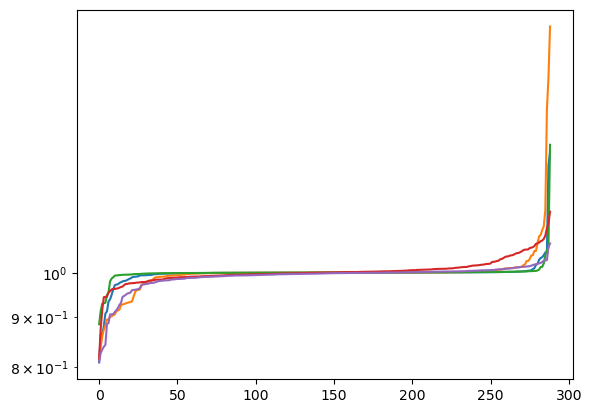

In [67]:
i = 1
for j in range(5):
    plt.semilogy(np.sort(all_est_params_list[j][:,i]/est_params_ref[:,i]))
all_est_params_list[j][:,i]/est_params_ref[:,i]

In [148]:
np.mean([np.min(hist[hist>0]) for hist in histories_DE_with_time]),np.mean([np.min(hist[hist>0]) for hist in histories_DE]),np.mean([np.min(hist[hist>0]) for hist in histories_local])

(np.float64(0.04415143776711063),
 np.float64(0.04385272653192745),
 np.float64(0.0545152221307126))

In [151]:
np.mean(np.array([np.min(hist[hist>0]) for hist in histories_local])/np.array([np.min(hist[hist>0]) for hist in histories_DE])>1.05)

np.float64(0.2491349480968858)

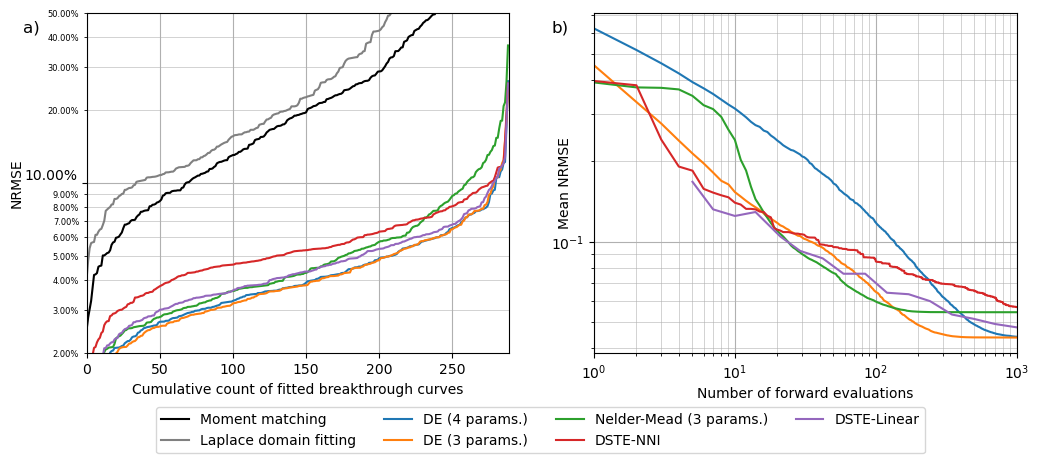

In [145]:
fig,axes = plt.subplots(ncols = 2, figsize = (12,5.0))

axes[0].semilogy(np.sort(RMSDs_moments), c = 'k',label ='Moment matching')
axes[0].semilogy(np.sort(RMSDs_laplace), c = 'gray',label ='Laplace domain fitting')
axes[0].semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_DE_with_time]),label ='DE (4 params.)')
axes[0].semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_DE]),label ='DE (3 params.)')
axes[0].semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_local]),label ='Nelder-Mead (3 params.)')
axes[0].semilogy(np.sort(RMSDs_NNI_full),label ='DSTE-NNI')
axes[0].semilogy(np.sort(RMSDs_linear_full),label ='DSTE-Linear')
axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))
axes[0].yaxis.set_minor_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))

axes[0].tick_params(axis='y', which='major', labelsize=10)
axes[0].tick_params(axis='y', which='minor', labelsize=6)
for label in axes[0].get_yticklabels():
    label.set_verticalalignment('bottom')

# axes[0].legend(ncols = 2)
axes[0].set_ylim(0.01,1.0)
axes[0].set_xlim(0,n_btcs)
axes[0].grid(which='major')
axes[0].grid(which='minor',linewidth = 0.4)
axes[0].set_xlabel('Cumulative count of fitted breakthrough curves')
axes[0].set_ylabel('NRMSE', labelpad= 0)
axes[0].set_ylim(0.02,0.5)

n_computed = n_btcs
j = np.argmin(abs(ns_synth_interm_linear-1000))
axes[1].loglog(np.arange(1000)+1,np.mean(np.minimum.accumulate(errors_DE_with_time[:n_computed],axis = 1),axis = 0))
axes[1].loglog(np.arange(1000)+1,np.mean(np.minimum.accumulate(errors_DE[:n_computed],axis = 1),axis = 0))
axes[1].loglog(np.arange(1000)+1,np.mean(np.minimum.accumulate(errors_local[:n_computed],axis = 1),axis = 0))
axes[1].loglog(np.arange(1000)+1,np.mean(RMSDs_NNI[:n_computed],axis = 0))
axes[1].loglog(ns_synth_interm_linear,np.mean(RMSDs_linear[:n_computed],axis = 0))
axes[1].grid()
axes[1].set_xlabel('Number of forward evaluations')
axes[1].set_ylabel('Mean NRMSE', labelpad = -15)
# axes[1].legend()
axes[1].grid(which = 'minor', linewidth = 0.4)
axes[1].set_xlim(1,1000)

axes[0].text(
    -0.15, 0.98, 'a)',
    transform=axes[0].transAxes,
    fontsize=12,
    va='top', ha='left'
)

axes[1].text(
    -0.1, 0.98, 'b)',
    transform=axes[1].transAxes,
    fontsize=12,
    va='top', ha='left'
)

handles,labels = axes[0].get_legend_handles_labels()
fig.legend(handles,labels, loc=(0.15,0.01), ncols = 4)
plt.subplots_adjust(bottom=0.2)



In [121]:
mean_RMSD_linear = np.mean(RMSDs_linear[:n_computed],axis = 0)[-1]

In [138]:
mean_RMSD_linear

np.float64(0.04786921547300072)

In [136]:
np.interp(mean_RMSD_linear,np.mean(np.minimum.accumulate(errors_DE_with_time[:n_computed],axis = 1),axis = 0)[::-1],np.arange(1000)[::-1]+1)

np.float64(549.014125789335)

In [137]:
np.interp(mean_RMSD_linear,np.mean(np.minimum.accumulate(errors_DE[:n_computed],axis = 1),axis = 0)[::-1],np.arange(1000)[::-1]+1)

np.float64(217.48025057307066)